In [1]:
import torch
import torch.nn as nn
torch.manual_seed(42)

# --------------------------------------------------
# 1. Créer les données
# --------------------------------------------------
periode = torch.linspace(0, 20, 200)
serie = torch.sin(periode)
longueur_sequence = 10
# Chaque entrée contient 10 valeurs.
# La cible est la valeur immédiatement suivante.
X = torch.stack([
    serie[i:i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])
y = torch.stack([
    serie[i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])
# Un RNN attend : (nombre de séquences, longueur, nombre de variables)
X = X.unsqueeze(-1)  # (190, 10, 1)
y = y.unsqueeze(-1)  # (190, 1)

# Découpage chronologique : début pour apprendre, fin pour tester.
X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]

Text(0, 0.5, 'y')

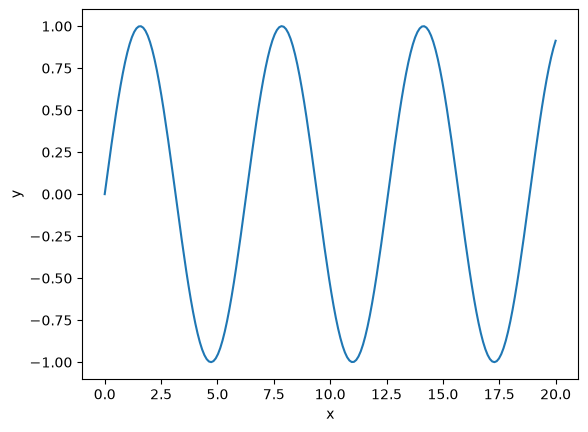

In [2]:
import matplotlib.pyplot as plt
plt.plot(periode, serie)
plt.xlabel("x")
plt.ylabel("y")

In [3]:
# --------------------------------------------------
# 2. Définir le modèle
# --------------------------------------------------

class SimpleRNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.rnn = nn.RNN(
            input_size=1,     # Une valeur à chaque instant
            hidden_size=16,   # Une mémoire composée de 16 nombres
            batch_first=True
        )

        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        # Si aucun état initial n'est fourni, PyTorch utilise des zéros.
        etats, _ = self.rnn(x)

        # etats : (nombre de séquences, 10, 16)
        dernier_etat = etats[:, -1, :]  # (nombre de séquences, 16)

        # Transformer la mémoire finale en une valeur prédite.
        return self.sortie(dernier_etat)


modele = SimpleRNN()
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele.parameters(), lr=0.01)

In [4]:
# --------------------------------------------------
# 3. Entraîner le modèle
# --------------------------------------------------

modele.train()

for epoch in range(300):
    predictions = modele(X_train)
    perte = critere(predictions, y_train)

    optimiseur.zero_grad()  # Effacer les anciens gradients
    perte.backward()       # Calculer les nouveaux gradients
    optimiseur.step()      # Mettre à jour les paramètres

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Erreur : {perte.item():.6f}")


# --------------------------------------------------
# 4. Tester le modèle
# --------------------------------------------------

modele.eval()

with torch.no_grad():
    predictions = modele(X_test)
    erreur_test = critere(predictions, y_test)

print(f"\nErreur de test : {erreur_test.item():.6f}")
print(f"Valeur réelle  : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions[0].item():.4f}")

Epoch  50 | Erreur : 0.001277
Epoch 100 | Erreur : 0.000504
Epoch 150 | Erreur : 0.000223
Epoch 200 | Erreur : 0.000103
Epoch 250 | Erreur : 0.000049
Epoch 300 | Erreur : 0.000025

Erreur de test : 0.000028
Valeur réelle  : -0.3639
Valeur prédite : -0.3601


In [5]:
predictions.shape

torch.Size([40, 1])

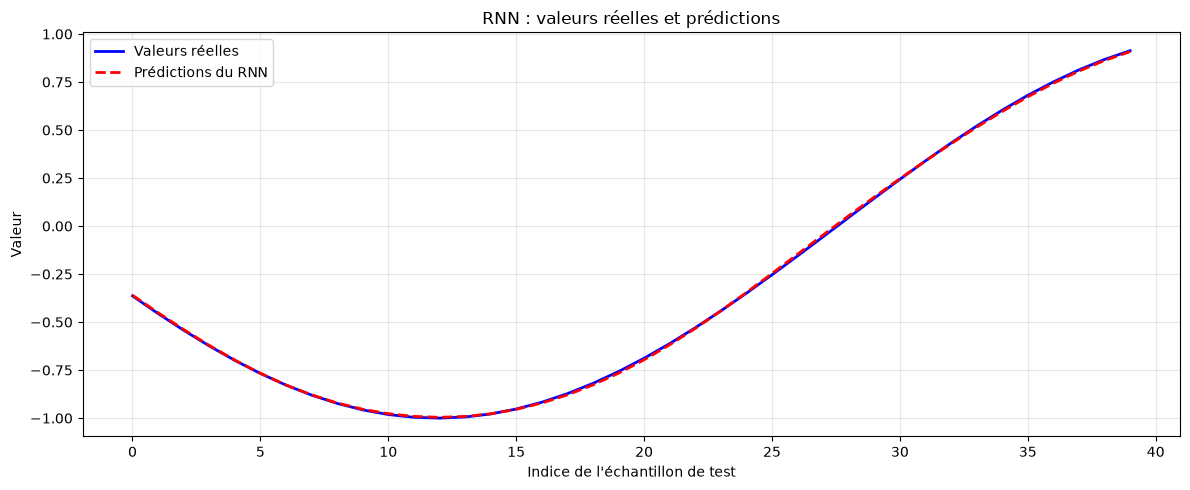

In [6]:
import matplotlib.pyplot as plt

# Convertir les tenseurs en tableaux NumPy
valeurs_reelles = y_test.detach().cpu().numpy().reshape(-1)
valeurs_predites = predictions.detach().cpu().numpy().reshape(-1)

# Tracer les deux courbes
plt.figure(figsize=(12, 5))

plt.plot(
    valeurs_reelles,
    label="Valeurs réelles",
    color="blue",
    linewidth=2
)

plt.plot(
    valeurs_predites,
    label="Prédictions du RNN",
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("RNN : valeurs réelles et prédictions")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
import torch
import torch.nn as nn

torch.manual_seed(42)

# --------------------------------------------------
# 1. Créer les données
# --------------------------------------------------

serie = torch.sin(torch.linspace(0, 20, 200))
longueur_sequence = 10

X = torch.stack([
    serie[i:i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

y = torch.stack([
    serie[i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

# Forme attendue : (nombre de séquences, longueur, variables)
X = X.unsqueeze(-1)  # (190, 10, 1)
y = y.unsqueeze(-1)  # (190, 1)

# Découpage chronologique
X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]


# --------------------------------------------------
# 2. Définir le modèle LSTM
# --------------------------------------------------

class SimpleLSTM(nn.Module):
    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=1,     # Une variable à chaque instant
            hidden_size=16,   # 16 unités cachées
            num_layers=1,     # Une seule couche LSTM
            batch_first=True
        )

        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        # Sans états initiaux fournis, h₀ et c₀ sont mis à zéro.
        etats, (h_final, c_final) = self.lstm(x)

        # etats : (nombre de séquences, 10, 16)
        dernier_etat = etats[:, -1, :]  # (nombre de séquences, 16)

        # Une prédiction par séquence
        return self.sortie(dernier_etat)


modele = SimpleLSTM()
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele.parameters(), lr=0.01)


# --------------------------------------------------
# 3. Entraîner le modèle
# --------------------------------------------------

modele.train()

for epoch in range(300):
    predictions = modele(X_train)
    perte = critere(predictions, y_train)

    optimiseur.zero_grad()
    perte.backward()
    optimiseur.step()

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Erreur : {perte.item():.6f}")


# --------------------------------------------------
# 4. Tester le modèle
# --------------------------------------------------

modele.eval()

with torch.no_grad():
    predictions = modele(X_test)
    erreur_test = critere(predictions, y_test)

print(f"\nErreur de test : {erreur_test.item():.6f}")
print(f"Valeur réelle  : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions[0].item():.4f}")

Epoch  50 | Erreur : 0.003562
Epoch 100 | Erreur : 0.000248
Epoch 150 | Erreur : 0.000043
Epoch 200 | Erreur : 0.000006
Epoch 250 | Erreur : 0.000004
Epoch 300 | Erreur : 0.000003

Erreur de test : 0.000003
Valeur réelle  : -0.3639
Valeur prédite : -0.3622


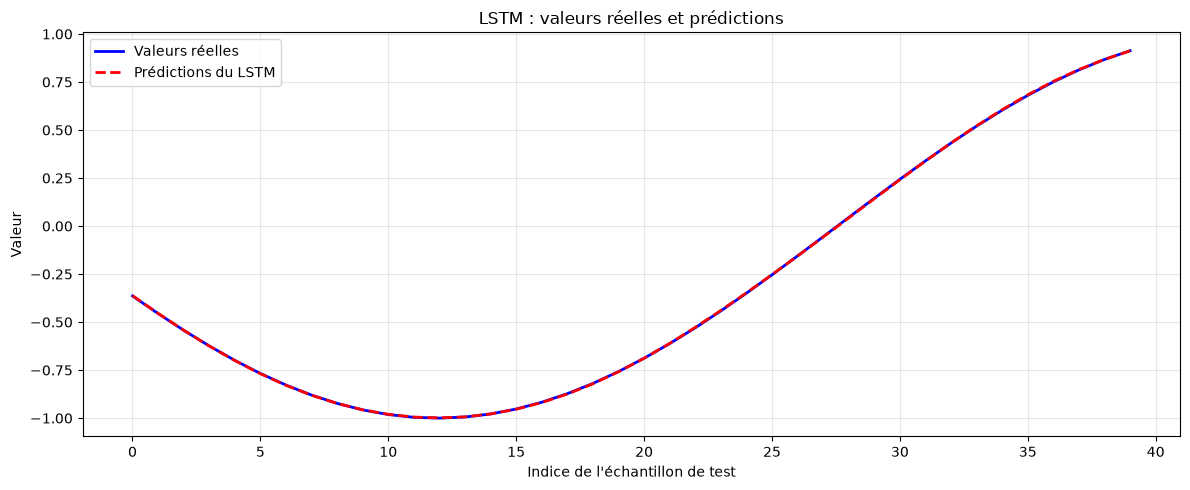

In [8]:
import matplotlib.pyplot as plt

# Convertir les tenseurs en tableaux NumPy
valeurs_reelles = y_test.detach().cpu().numpy().reshape(-1)
valeurs_predites = predictions.detach().cpu().numpy().reshape(-1)

# Tracer les deux courbes
plt.figure(figsize=(12, 5))

plt.plot(
    valeurs_reelles,
    label="Valeurs réelles",
    color="blue",
    linewidth=2
)

plt.plot(
    valeurs_predites,
    label="Prédictions du LSTM",
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("LSTM : valeurs réelles et prédictions")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [9]:
import torch
import torch.nn as nn

torch.manual_seed(42)

# --------------------------------------------------
# 1. Créer les données
# --------------------------------------------------

serie = torch.sin(torch.linspace(0, 20, 200))
longueur_sequence = 10

X = torch.stack([
    serie[i:i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

y = torch.stack([
    serie[i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

# Forme : (nombre de séquences, longueur, variables)
X = X.unsqueeze(-1)  # (190, 10, 1)
y = y.unsqueeze(-1)  # (190, 1)

# Découpage chronologique
X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]


# --------------------------------------------------
# 2. Définir le modèle Transformer
# --------------------------------------------------

class MiniTransformer(nn.Module):
    def __init__(self, longueur_max=10):
        super().__init__()

        dimension = 16

        # Transformer chaque valeur en un vecteur de 16 nombres.
        self.projection = nn.Linear(1, dimension)

        # Un vecteur appris pour chacune des 10 positions.
        self.positions = nn.Embedding(longueur_max, dimension)

        # Un bloc d'encodeur Transformer.
        couche = nn.TransformerEncoderLayer(
            d_model=dimension,       # Taille des représentations : 16
            nhead=2,                 # Deux têtes d'attention
            dim_feedforward=32,      # Taille interne du réseau feed-forward
            dropout=0.0,             # Désactivé pour simplifier l'exemple
            batch_first=True
        )

        self.encodeur = nn.TransformerEncoder(
            couche,
            num_layers=1
        )

        # Transformer la représentation finale en une prédiction.
        self.sortie = nn.Linear(dimension, 1)

    def forward(self, x):
        # x : (B, 10, 1)
        longueur = x.size(1)

        # 1. Projection des valeurs
        x = self.projection(x)  # (B, 10, 16)

        # 2. Ajout de l'information de position
        indices = torch.arange(longueur, device=x.device)
        positions = self.positions(indices)  # (10, 16)

        x = x + positions.unsqueeze(0)  # (B, 10, 16)

        # 3. Mise en relation des valeurs par auto-attention
        representations = self.encodeur(x)  # (B, 10, 16)

        # 4. Récupérer la représentation de la dernière position
        derniere_position = representations[:, -1, :]  # (B, 16)

        # 5. Prédire la valeur suivante
        return self.sortie(derniere_position)  # (B, 1)


modele = MiniTransformer(longueur_max=longueur_sequence)
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele.parameters(), lr=0.01)


# --------------------------------------------------
# 3. Entraîner le modèle
# --------------------------------------------------

modele.train()

for epoch in range(300):
    predictions = modele(X_train)
    perte = critere(predictions, y_train)

    optimiseur.zero_grad()
    perte.backward()
    optimiseur.step()

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Erreur : {perte.item():.6f}")


# --------------------------------------------------
# 4. Tester le modèle
# --------------------------------------------------

modele.eval()

with torch.no_grad():
    predictions = modele(X_test)
    erreur_test = critere(predictions, y_test)

print(f"\nErreur de test : {erreur_test.item():.6f}")
print(f"Valeur réelle  : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions[0].item():.4f}")

Epoch  50 | Erreur : 0.001504
Epoch 100 | Erreur : 0.000110
Epoch 150 | Erreur : 0.000026
Epoch 200 | Erreur : 0.000012
Epoch 250 | Erreur : 0.000007
Epoch 300 | Erreur : 0.000004

Erreur de test : 0.000006
Valeur réelle  : -0.3639
Valeur prédite : -0.3662


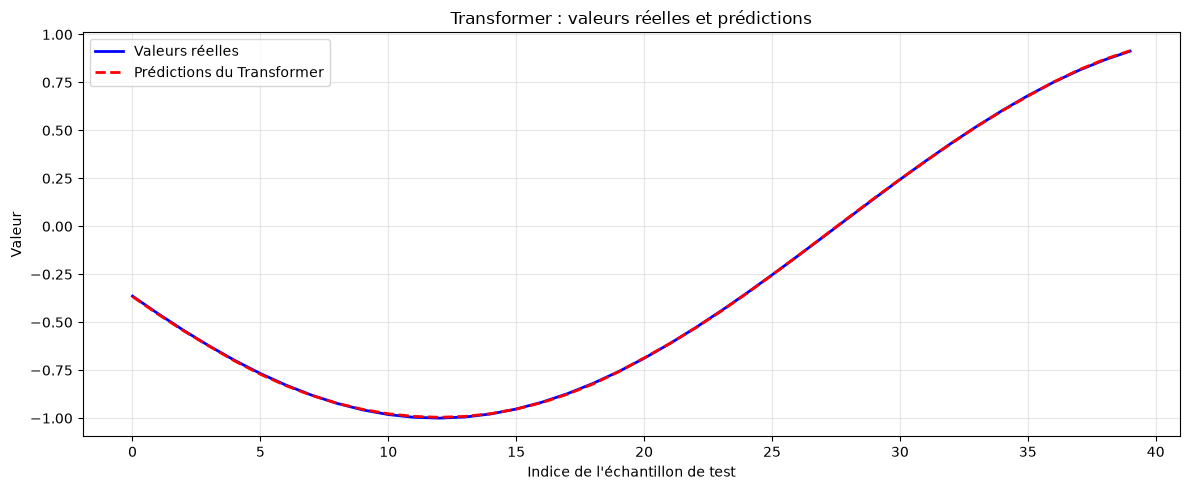

In [10]:
import matplotlib.pyplot as plt

# Convertir les tenseurs en tableaux NumPy
valeurs_reelles = y_test.detach().cpu().numpy().reshape(-1)
valeurs_predites = predictions.detach().cpu().numpy().reshape(-1)

# Tracer les deux courbes
plt.figure(figsize=(12, 5))

plt.plot(
    valeurs_reelles,
    label="Valeurs réelles",
    color="blue",
    linewidth=2
)

plt.plot(
    valeurs_predites,
    label="Prédictions du Transformer",
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("Transformer : valeurs réelles et prédictions")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

exercice 1


In [11]:
import numpy as np
import pandas as pd
import torch
from torch.utils.data import TensorDataset, DataLoader

df = pd.read_csv(
    "data/household_power_consumption.txt",
    sep=";",
    na_values=["?"],
    low_memory=False,
)

df["datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S",
)

puissance = pd.to_numeric(df["Global_active_power"], errors="coerce")
puissance.index = pd.DatetimeIndex(df["datetime"])

# Puissance moyenne horaire : conserver les heures suffisamment renseignées.
horaire = puissance.resample("h").agg(["mean", "count"])
serie = horaire["mean"].where(horaire["count"] >= 45)

# Découpage chronologique : 70 % entraînement, 15 % validation, 15 % test.
n = len(serie)
fin_train = int(0.70 * n)
fin_val = int(0.85 * n)

# Normalisation calculée uniquement sur l'entraînement.
moyenne = serie.iloc[:fin_train].mean()
ecart_type = serie.iloc[:fin_train].std()
valeurs = ((serie - moyenne) / ecart_type).to_numpy()

# Une entrée contient 24 heures consécutives.
# Écarter les fenêtres comportant des valeurs manquantes.
fenetre = 24
X, y, dates_cibles = [], [], []

for i in range(fenetre, n):
    sequence = valeurs[i - fenetre:i]
    cible = valeurs[i]

    if np.isfinite(sequence).all() and np.isfinite(cible):
        X.append(sequence)
        y.append(cible)
        dates_cibles.append(i)

X = torch.tensor(np.array(X), dtype=torch.float32).unsqueeze(-1)
y = torch.tensor(np.array(y), dtype=torch.float32).unsqueeze(-1)
dates_cibles = np.array(dates_cibles)

train_mask = dates_cibles < fin_train
val_mask = (dates_cibles >= fin_train) & (dates_cibles < fin_val)
test_mask = dates_cibles >= fin_val

train_loader = DataLoader(
    TensorDataset(X[train_mask], y[train_mask]),
    batch_size=64,
    shuffle=True,
)
val_loader = DataLoader(
    TensorDataset(X[val_mask], y[val_mask]),
    batch_size=64,
)
test_loader = DataLoader(
    TensorDataset(X[test_mask], y[test_mask]),
    batch_size=64,
)

In [12]:
print(X.shape, y.shape)
print("train :", train_mask.sum(), "| val :", val_mask.sum(), "| test :", test_mask.sum())

torch.Size([33791, 24, 1]) torch.Size([33791, 1])
train : 23805 | val : 5054 | test : 4932


In [13]:
import copy
import torch.nn as nn

class EnergyTransformer(nn.Module):
    def __init__(self, fenetre=24, dimension=32):
        super().__init__()
        self.projection = nn.Linear(1, dimension)
        self.positions = nn.Embedding(fenetre, dimension)   # encodage positionnel des 24 heures
        couche = nn.TransformerEncoderLayer(
            d_model=dimension,
            nhead=4,
            dim_feedforward=128,
            dropout=0.1,
            batch_first=True,
        )
        self.encodeur = nn.TransformerEncoder(couche, num_layers=2)
        self.sortie = nn.Linear(dimension, 1)

    def forward(self, x):                                   # (B, 24, 1)
        indices = torch.arange(x.size(1), device=x.device)
        x = self.projection(x)                              # (B, 24, 32)
        x = x + self.positions(indices).unsqueeze(0)        # (B, 24, 32)
        x = self.encodeur(x)                                # (B, 24, 32)
        return self.sortie(x[:, -1, :])                     # (B, 1)

modele = EnergyTransformer()
print(modele(torch.randn(8, 24, 1)).shape)   # attendu : torch.Size([8, 1])

torch.Size([8, 1])


In [14]:
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele.parameters(), lr=0.001)

def perte_moyenne(modele, loader):
    modele.eval()
    total, n = 0.0, 0
    with torch.no_grad():
        for xb, yb in loader:
            total += critere(modele(xb), yb).item() * len(xb)
            n += len(xb)
    return total / n

meilleure_perte = float("inf")
meilleur_etat = None

for epoch in range(20):
    modele.train()
    total, n = 0.0, 0
    for xb, yb in train_loader:
        optimiseur.zero_grad()
        perte = critere(modele(xb), yb)
        perte.backward()
        optimiseur.step()
        total += perte.item() * len(xb)
        n += len(xb)

    perte_val = perte_moyenne(modele, val_loader)
    marque = ""
    if perte_val < meilleure_perte:
        meilleure_perte = perte_val
        meilleur_etat = copy.deepcopy(modele.state_dict())
        marque = "  <- meilleur"
    print(f"Epoch {epoch + 1:2d} | train {total / n:.4f} | val {perte_val:.4f}{marque}")

# Garder le modèle qui a la meilleure perte de validation
modele.load_state_dict(meilleur_etat)
print(f"\nMeilleure perte de validation : {meilleure_perte:.4f}")

Epoch  1 | train 0.4602 | val 0.4119  <- meilleur
Epoch  2 | train 0.4288 | val 0.3982  <- meilleur
Epoch  3 | train 0.4243 | val 0.4014
Epoch  4 | train 0.4198 | val 0.3941  <- meilleur
Epoch  5 | train 0.4157 | val 0.3894  <- meilleur
Epoch  6 | train 0.4130 | val 0.3882  <- meilleur
Epoch  7 | train 0.4102 | val 0.3840  <- meilleur
Epoch  8 | train 0.4067 | val 0.3833  <- meilleur
Epoch  9 | train 0.4077 | val 0.3844
Epoch 10 | train 0.4080 | val 0.3954
Epoch 11 | train 0.4061 | val 0.3801  <- meilleur
Epoch 12 | train 0.4037 | val 0.3903
Epoch 13 | train 0.4047 | val 0.3836
Epoch 14 | train 0.4022 | val 0.3791  <- meilleur
Epoch 15 | train 0.3995 | val 0.3758  <- meilleur
Epoch 16 | train 0.3989 | val 0.3731  <- meilleur
Epoch 17 | train 0.3968 | val 0.3869
Epoch 18 | train 0.3961 | val 0.3800
Epoch 19 | train 0.3950 | val 0.3833
Epoch 20 | train 0.3952 | val 0.3813

Meilleure perte de validation : 0.3731


In [15]:
modele.eval()
preds, cibles = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        preds.append(modele(xb))
        cibles.append(yb)

# Retour à l'échelle originale (kW)
pred = torch.cat(preds).numpy().ravel() * ecart_type + moyenne
reel = torch.cat(cibles).numpy().ravel() * ecart_type + moyenne

X_test = X[test_mask]
persistance = X_test[:, -1, 0].numpy() * ecart_type + moyenne   # dernière heure observée
journaliere = X_test[:, 0, 0].numpy() * ecart_type + moyenne    # valeur 24 h avant la cible

def mae(a, b):
    return np.mean(np.abs(a - b))

def rmse(a, b):
    return np.sqrt(np.mean((a - b) ** 2))

resultats = pd.DataFrame(
    {
        "MAE (kW)": [mae(pred, reel), mae(persistance, reel), mae(journaliere, reel)],
        "RMSE (kW)": [rmse(pred, reel), rmse(persistance, reel), rmse(journaliere, reel)],
    },
    index=["Transformer", "Persistance", "Référence journalière"],
)
print(resultats.round(4))

                       MAE (kW)  RMSE (kW)
Transformer              0.3461     0.4936
Persistance              0.3892     0.5884
Référence journalière    0.5133     0.7639


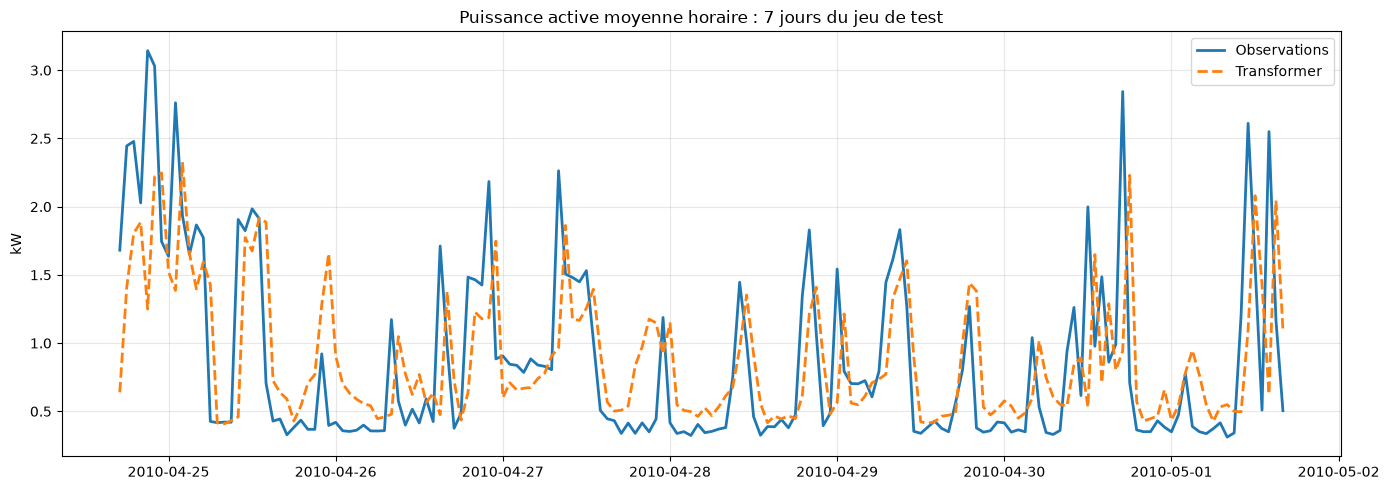

In [16]:
import matplotlib.pyplot as plt

indices_test = dates_cibles[test_mask]
dates = serie.index[indices_test]

# Les fenêtres avec des trous ont été supprimées : on cherche 168 heures consécutives.
debut = next(
    k for k in range(len(indices_test) - 167)
    if indices_test[k + 167] - indices_test[k] == 167
)
fin = debut + 168

plt.figure(figsize=(14, 5))
plt.plot(dates[debut:fin], reel[debut:fin], label="Observations", linewidth=2)
plt.plot(dates[debut:fin], pred[debut:fin], "--", label="Transformer", linewidth=2)
plt.title("Puissance active moyenne horaire : 7 jours du jeu de test")
plt.ylabel("kW")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Questions de réflexion

**1. Le Transformer améliore-t-il les deux références ?**
D'après le tableau, MAE = ... kW et RMSE = ... kW pour le Transformer, contre ... / ... pour la persistance et ... / ... pour la référence journalière. Le Transformer améliore (ou non) ces références : ...

**2. Une fenêtre de 168 heures capte-t-elle mieux les habitudes hebdomadaires ?**
Oui en principe : 168 h couvrent une semaine entière, le modèle voit donc la différence entre la semaine et le week-end. En contrepartie, le coût de l'attention augmente avec le carré de la longueur, il reste moins de fenêtres sans valeur manquante, et il faut passer à Embedding(168, 32).

**3. Intérêt d'ajouter l'heure de la journée et le jour de la semaine ?**
Le modèle reçoit directement le contexte du calendrier (pic du soir, week-end) au lieu de devoir le déduire des 24 valeurs. On les encode en sin/cos pour garder leur caractère cyclique (23 h est proche de 0 h).

**4. Pourquoi normaliser uniquement à partir de l'entraînement ?**
Pour éviter une fuite de données : la moyenne et l'écart-type calculés sur la validation ou le test contiendraient de l'information sur le futur. En conditions réelles, les valeurs futures sont inconnues au moment de l'entraînement.

**5. Comment prédire une énergie en kWh ?**
Énergie (kWh) = puissance moyenne (kW) × durée (h). Sur une heure complète, la valeur est numériquement la même. On peut aussi additionner les mesures minute par minute divisées par 60 (`resample("h").sum() / 60`), en gérant les minutes manquantes (seuil count >= 45, ou mise à l'échelle par 60 / count).

exercice 2


In [17]:
import torch

with open("data/corpus.txt", encoding="utf-8") as fichier:
    texte = fichier.read()

# Retirer l'en-tête et la licence anglaise de Project Gutenberg
debut = texte.find("*** START")
fin = texte.find("*** END")
if debut != -1 and fin != -1:
    texte = texte[texte.find("\n", debut) + 1:fin]

caracteres = sorted(set(texte))
stoi = {c: i for i, c in enumerate(caracteres)}
itos = {i: c for c, i in stoi.items()}

tokens = torch.tensor([stoi[c] for c in texte], dtype=torch.long)

# Exemple d'une paire entrée/cible
longueur = 64
x = tokens[:longueur]
y = tokens[1:longueur + 1]

taille_vocab = len(caracteres)
print("Nombre de caractères :", len(texte))
print("Taille du vocabulaire :", taille_vocab)
print("Entrée :", repr("".join(itos[i] for i in x[:20].tolist())))
print("Cible  :", repr("".join(itos[i] for i in y[:20].tolist())))

Nombre de caractères : 658321
Taille du vocabulaire : 101
Entrée : '\n\n\n\nProduced by www.'
Cible  : '\n\n\nProduced by www.e'


In [18]:
import torch.nn as nn

class BlocGPT(nn.Module):
    def __init__(self, d_model=64, n_tetes=4, dropout=0.1):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)                      # normalisation avant l'attention
        self.attention = nn.MultiheadAttention(
            d_model, n_tetes, dropout=dropout, batch_first=True
        )
        self.ln2 = nn.LayerNorm(d_model)                      # seconde normalisation
        self.mlp = nn.Sequential(
            nn.Linear(d_model, 4 * d_model),                  # 64 -> 256
            nn.GELU(),
            nn.Linear(4 * d_model, d_model),                  # 256 -> 64
            nn.Dropout(dropout),
        )

    def forward(self, x):
        T = x.shape[1]
        # Masque causal : True = relation interdite (regarder le futur)
        masque = torch.triu(
            torch.ones(T, T, dtype=torch.bool, device=x.device),
            diagonal=1,
        )
        h = self.ln1(x)
        a, _ = self.attention(h, h, h, attn_mask=masque, need_weights=False)
        x = x + a                                             # 1re connexion résiduelle
        x = x + self.mlp(self.ln2(x))                         # 2e connexion résiduelle
        return x


class MiniGPT(nn.Module):
    def __init__(self, taille_vocab, d_model=64, n_tetes=4, n_blocs=2, longueur_max=64):
        super().__init__()
        self.tokens = nn.Embedding(taille_vocab, d_model)       # embeddings de caractères
        self.positions = nn.Embedding(longueur_max, d_model)    # embeddings de positions
        self.blocs = nn.ModuleList([BlocGPT(d_model, n_tetes) for _ in range(n_blocs)])
        self.ln_final = nn.LayerNorm(d_model)
        self.tete = nn.Linear(d_model, taille_vocab)            # projection vers le vocabulaire

    def forward(self, ids):                                     # (B, T)
        T = ids.shape[1]
        pos = torch.arange(T, device=ids.device)
        x = self.tokens(ids) + self.positions(pos)              # (B, T, 64)
        for bloc in self.blocs:
            x = bloc(x)
        return self.tete(self.ln_final(x))                      # (B, T, taille_vocab)

In [19]:
gpt = MiniGPT(taille_vocab)
ids = torch.stack([x, x])                                       # batch de 2

rep = gpt.tokens(ids) + gpt.positions(torch.arange(longueur))
for bloc in gpt.blocs:
    rep = bloc(rep)

print("Identifiants     :", ids.shape)                  # (2, 64)
print("Représentations  :", rep.shape)                  # (2, 64, 64)
print("Logits           :", gpt(ids).shape)             # (2, 64, taille_vocab)
print("Cibles           :", torch.stack([y, y]).shape)  # (2, 64)

Identifiants     : torch.Size([2, 64])
Représentations  : torch.Size([2, 64, 64])
Logits           : torch.Size([2, 64, 101])
Cibles           : torch.Size([2, 64])


In [20]:
torch.manual_seed(42)

def lot(taille_lot=32):
    debuts = torch.randint(0, len(tokens) - longueur - 1, (taille_lot,))
    xb = torch.stack([tokens[i:i + longueur] for i in debuts])
    yb = torch.stack([tokens[i + 1:i + longueur + 1] for i in debuts])   # cibles décalées d'un caractère
    return xb, yb

gpt = MiniGPT(taille_vocab)
optimiseur = torch.optim.AdamW(gpt.parameters(), lr=1e-3)
critere = nn.CrossEntropyLoss()

for etape in range(3000):
    gpt.train()
    xb, yb = lot()
    logits = gpt(xb)                                                      # (32, 64, V)
    perte = critere(logits.reshape(-1, taille_vocab), yb.reshape(-1))     # perte sur toutes les positions

    optimiseur.zero_grad()
    perte.backward()
    optimiseur.step()

    if (etape + 1) % 300 == 0:
        print(f"Étape {etape + 1:4d} | perte {perte.item():.3f}")

Étape  300 | perte 2.445
Étape  600 | perte 2.249
Étape  900 | perte 2.084
Étape 1200 | perte 2.023
Étape 1500 | perte 1.996
Étape 1800 | perte 1.922
Étape 2100 | perte 1.826
Étape 2400 | perte 1.840
Étape 2700 | perte 1.777
Étape 3000 | perte 1.770


In [21]:
@torch.no_grad()
def generer(modele, amorce, n=200, temperature=1.0):
    modele.eval()
    ids = torch.tensor([[stoi[c] for c in amorce if c in stoi]], dtype=torch.long)
    for _ in range(n):
        contexte = ids[:, -longueur:]                         # au plus 64 caractères
        logits = modele(contexte)[:, -1, :] / temperature     # dernière position
        probas = torch.softmax(logits, dim=-1)
        suivant = torch.multinomial(probas, num_samples=1)    # échantillonnage
        ids = torch.cat([ids, suivant], dim=1)
    return "".join(itos[i] for i in ids[0].tolist())

amorce = "Le soir, "
for t in [0.5, 1.0, 1.5]:
    torch.manual_seed(0)
    print(f"===== Température {t} =====")
    print(generer(gpt, amorce, 200, t))
    print()

===== Température 0.5 =====
Le soir, et la maire pos
contres de contendresses de la monsieur de la contine de les partites de la présins des le probes de la pris hambre et de par chaut son de bremire, et les prents de l'instins de la
voi

===== Température 1.0 =====
Le soir, heura maire pos
ce qui nouscès distique, il                                         toutres traisssembs! c que voint l'onnui humme, ensidérait
droiss. Si Ma catins homment fint-du, l'in maisqui l, ava

===== Température 1.5 =====
Le soir, heura Javelle: 
DiVala Toubcèster;».

--Yn restnenors? Nepoure quelques te sons qui à cire M. Il faimbm! v avouvonnêt
JoJwi: havai, ensidéraites, proffrion
et trarm. Alla uf ne
sur l'in m'inqui l, avo



In [22]:
gpt.eval()
with torch.no_grad():
    sequence = tokens[:longueur].unsqueeze(0)                     # (1, 64)
    modifiee = sequence.clone()
    modifiee[0, -1] = (modifiee[0, -1] + 1) % taille_vocab        # changer le dernier caractère (futur)

    logits_1 = gpt(sequence)
    logits_2 = gpt(modifiee)

print("Positions précédentes inchangées :",
      torch.allclose(logits_1[:, :-1], logits_2[:, :-1], atol=1e-5))   # attendu : True
print("Dernière position modifiée       :",
      not torch.allclose(logits_1[:, -1], logits_2[:, -1]))             # attendu : True

Positions précédentes inchangées : True
Dernière position modifiée       : True


### Questions

**Que se passe-t-il si le masque causal est supprimé ?**
Chaque position peut regarder les caractères suivants, donc le caractère qu'elle doit prédire. Le modèle « triche » : la perte d'entraînement chute presque à zéro, mais il n'a rien appris d'utile. À la génération, le futur n'existe pas encore, donc il produit du texte incohérent (décalage entre entraînement et génération).

**Quel effet a la température ?**
Les logits sont divisés par T avant le softmax. Avec T < 1 (0.5), la distribution est plus concentrée : le texte est plus prudent et plus correct, mais aussi plus répétitif. Avec T = 1, on échantillonne la distribution apprise. Avec T > 1 (1.5), la distribution est aplatie : le texte est plus varié, mais avec beaucoup plus de fautes et de caractères au hasard.

**Pourquoi décaler les cibles d'une position ?**
La tâche consiste à prédire le caractère suivant. La position t a vu les caractères 0 à t, et sa cible est le caractère t+1. Sans décalage, la cible serait le caractère déjà présent à l'entrée : le modèle apprendrait simplement à le recopier.

exercice 3

In [23]:
import random
random.seed(0)

animaux = ["le chat", "le chien", "le cheval", "le lapin"]
personnes = ["le professeur", "la voisine", "mon frère", "ma sœur", "le garçon",
             "la fille", "le médecin", "mon père", "ma mère"]
pieces = ["la cuisine", "le salon", "le jardin"]
villes_maroc = ["casablanca", "rabat", "marrakech", "tanger"]

phrases = set()
for a in animaux:
    for lieu in ["le canapé", "le lit", "le tapis"]:
        phrases.add(f"{a} dort sur {lieu}")
for s in animaux + personnes:
    for n in ["une pomme", "du pain", "une orange", "du fromage"]:
        for p in pieces:
            phrases.add(f"{s} mange {n} dans {p}")
for s in personnes:
    for l in ["un livre", "le journal", "une lettre"]:
        for p in pieces:
            phrases.add(f"{s} lit {l} dans {p}")
    for b in ["du café", "du thé", "du lait", "du jus"]:
        for m in ["matin", "soir"]:
            phrases.add(f"{s} boit {b} le {m}")
    for lieu in ["marché", "travail", "stade"]:
        for t in ["bus", "voiture", "train", "vélo"]:
            phrases.add(f"{s} va au {lieu} en {t}")
for v in villes_maroc + ["paris"]:
    for meteo in ["beau", "froid", "chaud"]:
        for m in ["matin", "soir"]:
            phrases.add(f"il fait {meteo} à {v} ce {m}")
for v in villes_maroc:
    phrases.add(f"{v} est une ville du maroc")
phrases.add("paris est une ville de france")

phrases = sorted(phrases)
random.shuffle(phrases)
with open("data/phrases.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(phrases))

print(len(phrases), "phrases")
print(phrases[:5])

464 phrases
['ma sœur boit du lait le matin', 'mon frère lit un livre dans la cuisine', 'la voisine mange une pomme dans le salon', 'ma sœur lit le journal dans la cuisine', 'mon père va au travail en bus']


In [24]:
import torch

PAD, UNK, CLS, SEP, MASK = 0, 1, 2, 3, 4
SPECIAUX = ["[PAD]", "[UNK]", "[CLS]", "[SEP]", "[MASK]"]
LONGUEUR = 32

with open("data/phrases.txt", encoding="utf-8") as f:
    phrases = [ligne.strip() for ligne in f if ligne.strip()]

# 90 % entraînement, 10 % validation
coupure = int(0.9 * len(phrases))
phrases_train, phrases_val = phrases[:coupure], phrases[coupure:]

# Vocabulaire construit uniquement sur l'entraînement
mots = sorted({m for p in phrases_train for m in p.split()})
itos_mots = SPECIAUX + mots
stoi_mots = {m: i for i, m in enumerate(itos_mots)}
taille_vocabulaire = len(itos_mots)

def encoder(phrase):
    mots_ids = [stoi_mots.get(m, UNK) for m in phrase.split()][:LONGUEUR - 2]
    ids = [CLS] + mots_ids + [SEP]
    return ids + [PAD] * (LONGUEUR - len(ids))

ids_train = torch.tensor([encoder(p) for p in phrases_train])
ids_val = torch.tensor([encoder(p) for p in phrases_val])

print("Taille du vocabulaire :", taille_vocabulaire)
print("ids_train :", ids_train.shape, "| ids_val :", ids_val.shape)
print(" ".join(itos_mots[i] for i in ids_train[0].tolist()))

Taille du vocabulaire : 76
ids_train : torch.Size([417, 32]) | ids_val : torch.Size([47, 32])
[CLS] ma sœur boit du lait le matin [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]


In [25]:
def masquer(input_ids, proportion=0.15, generateur=None):
    """Renvoie (ids corrompus, positions sélectionnées)."""
    ordinaires = input_ids >= 5                       # exclut PAD, UNK, CLS, SEP, MASK
    tirage = torch.rand(input_ids.shape, generator=generateur)
    selection = (tirage < proportion) & ordinaires

    # Au moins une position sélectionnée par phrase
    for i in range(input_ids.size(0)):
        if ordinaires[i].any() and not selection[i].any():
            candidats = ordinaires[i].nonzero(as_tuple=True)[0]
            j = candidats[torch.randint(len(candidats), (1,), generator=generateur)]
            selection[i, j] = True

    corrompus = input_ids.clone()
    r = torch.rand(input_ids.shape, generator=generateur)
    a_masquer = selection & (r < 0.8)                     # 80 % -> [MASK]
    a_remplacer = selection & (r >= 0.8) & (r < 0.9)      # 10 % -> token ordinaire aléatoire
    # les 10 % restants sont conservés inchangés
    corrompus[a_masquer] = MASK
    aleatoires = torch.randint(5, taille_vocabulaire, input_ids.shape, generator=generateur)
    corrompus[a_remplacer] = aleatoires[a_remplacer]
    return corrompus, selection

# Vérification des proportions
c, s = masquer(ids_train)
print("Tokens ordinaires sélectionnés :", round(s.sum().item() / (ids_train >= 5).sum().item(), 3))
print("Part remplacée par [MASK]      :", round((c[s] == MASK).float().mean().item(), 3))
print("Part inchangée                 :", round((c[s] == ids_train[s]).float().mean().item(), 3))

Tokens ordinaires sélectionnés : 0.198
Part remplacée par [MASK]      : 0.796
Part inchangée                 : 0.11


In [26]:
import torch.nn as nn

class MiniBERT(nn.Module):
    def __init__(self, taille_vocabulaire, d_model=64, n_tetes=4, n_couches=2, longueur_max=32):
        super().__init__()
        self.tokens = nn.Embedding(taille_vocabulaire, d_model, padding_idx=PAD)
        self.positions = nn.Embedding(longueur_max, d_model)
        self.norme = nn.LayerNorm(d_model)
        couche = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_tetes,
            dim_feedforward=4 * d_model,
            dropout=0.1,
            batch_first=True,
        )
        self.encodeur = nn.TransformerEncoder(couche, num_layers=n_couches, enable_nested_tensor=False)
        self.tete = nn.Linear(d_model, taille_vocabulaire)      # projection vers le vocabulaire

    def forward(self, ids, masque_padding=None):
        if masque_padding is None:
            masque_padding = ids == PAD                          # True = position ignorée
        pos = torch.arange(ids.size(1), device=ids.device)
        x = self.norme(self.tokens(ids) + self.positions(pos))   # (B, 32, 64)
        # Attention bidirectionnelle : masque de padding, mais AUCUN masque causal
        x = self.encodeur(x, src_key_padding_mask=masque_padding)
        return self.tete(x)                                      # (B, 32, taille_vocabulaire)

In [27]:
torch.manual_seed(0)
bert = MiniBERT(taille_vocabulaire)
optimiseur = torch.optim.AdamW(bert.parameters(), lr=1e-3)
critere = torch.nn.CrossEntropyLoss(ignore_index=-100)

# Validation : masquée une seule fois, pour que la mesure soit stable
g = torch.Generator().manual_seed(123)
val_corrompus, val_selection = masquer(ids_val, generateur=g)

def exactitude_val(modele):
    modele.eval()
    with torch.no_grad():
        pred = modele(val_corrompus).argmax(dim=-1)
    return (pred[val_selection] == ids_val[val_selection]).float().mean().item()

for epoch in range(100):
    bert.train()
    permutation = torch.randperm(len(ids_train))
    total, n_lots = 0.0, 0
    for k in range(0, len(ids_train), 32):
        input_ids = ids_train[permutation[k:k + 32]]
        corrompus, positions_selectionnees = masquer(input_ids)   # nouveau masquage à chaque fois

        # Perte uniquement sur les positions sélectionnées (y compris celles inchangées)
        labels = input_ids.clone()
        labels[~positions_selectionnees] = -100

        logits = bert(corrompus)
        loss = critere(logits.reshape(-1, taille_vocabulaire), labels.reshape(-1))

        optimiseur.zero_grad()
        loss.backward()
        optimiseur.step()
        total += loss.item()
        n_lots += 1

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch + 1:3d} | perte {total / n_lots:.3f} | exactitude val {exactitude_val(bert):.1%}")

Epoch  10 | perte 1.355 | exactitude val 62.0%
Epoch  20 | perte 0.830 | exactitude val 73.2%
Epoch  30 | perte 0.627 | exactitude val 76.1%
Epoch  40 | perte 0.532 | exactitude val 80.3%
Epoch  50 | perte 0.525 | exactitude val 78.9%
Epoch  60 | perte 0.555 | exactitude val 80.3%
Epoch  70 | perte 0.511 | exactitude val 74.6%
Epoch  80 | perte 0.486 | exactitude val 83.1%
Epoch  90 | perte 0.425 | exactitude val 87.3%
Epoch 100 | perte 0.627 | exactitude val 77.5%


In [28]:
bert.eval()
with torch.no_grad():
    logits = bert(val_corrompus)

for i in range(6):
    vue = " ".join(itos_mots[t] for t in val_corrompus[i].tolist() if t != PAD)
    print(vue)
    for p in val_selection[i].nonzero(as_tuple=True)[0].tolist():
        probas = torch.softmax(logits[i, p], dim=-1)
        top = torch.topk(probas, 3)
        propositions = ", ".join(
            f"{itos_mots[t]} ({pr:.0%})" for pr, t in zip(top.values.tolist(), top.indices.tolist())
        )
        print(f"   attendu : {itos_mots[ids_val[i, p].item()]:<10} | top 3 : {propositions}")
    print()

[CLS] le professeur mange [MASK] pomme dans [MASK] jardin [SEP]
   attendu : une        | top 3 : une (100%), le (0%), du (0%)
   attendu : dans       | top 3 : dans (100%), pomme (0%), un (0%)
   attendu : le         | top 3 : le (100%), la (0%), une (0%)

[CLS] la voisine va [MASK] marché stade vélo [SEP]
   attendu : au         | top 3 : au (100%), va (0%), à (0%)
   attendu : en         | top 3 : en (99%), le (0%), vélo (0%)

[CLS] ma mère va [MASK] marché en voiture [SEP]
   attendu : au         | top 3 : au (100%), va (0%), marché (0%)

[CLS] ma mère lit une lettre dans le salon [SEP]
   attendu : lettre     | top 3 : lettre (97%), mon (1%), orange (0%)

[CLS] le garçon boit du [MASK] le soir [SEP]
   attendu : jus        | top 3 : lait (35%), café (26%), thé (24%)

[CLS] le lait lit le journal dans la cuisine [SEP]
   attendu : médecin    | top 3 : professeur (34%), médecin (29%), garçon (19%)



In [29]:
bert.eval()
masque_padding = ids_val == PAD

# Changer les valeurs aux positions de padding, en gardant le MÊME masque
modifies = val_corrompus.clone()
modifies[masque_padding] = torch.randint(5, taille_vocabulaire, (int(masque_padding.sum()),))

with torch.no_grad():
    logits_1 = bert(val_corrompus, masque_padding)
    logits_2 = bert(modifies, masque_padding)

utiles = ~masque_padding
print("Prédictions des tokens utiles inchangées :",
      torch.allclose(logits_1[utiles], logits_2[utiles], atol=1e-5))   # attendu : True

Prédictions des tokens utiles inchangées : True


### Questions

**Pourquoi BERT peut-il utiliser le contexte à droite du mot masqué ?**
L'encodeur n'a pas de masque causal : chaque position voit tous les tokens non-padding, à gauche comme à droite (attention bidirectionnelle). Ce n'est pas de la triche, car le mot à prédire est caché dans l'entrée (remplacé par [MASK], ou par un mot aléatoire). Le modèle doit donc le déduire du contexte des deux côtés.

**Pourquoi calculer la perte uniquement sur les positions sélectionnées ?**
Les autres positions sont visibles telles quelles dans l'entrée : les prédire reviendrait à recopier l'entrée, ce qui est trivial et dominerait la perte. On garde quand même les 10 % de tokens sélectionnés mais inchangés : le modèle ne peut pas supposer qu'un mot visible est toujours correct, il doit construire une bonne représentation de chaque token.

**Pourquoi ce modèle ne génère-t-il pas du texte comme GPT ?**
Il est entraîné à compléter des trous à partir des deux côtés, pas à prédire le token suivant à partir de la gauche seulement. Il n'a pas de structure causale ni de boucle autorégressive. Générer avec lui demanderait d'ajouter des [MASK] et de les remplir un par un, ce qui est lent et ne correspond pas à son entraînement.